# 🐼 Belajar Pandas Lengkap & Praktis (75 Topik Komprehensif)
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

Notebook komprehensif 75 topik manipulasi data, analisis statistik, transformasi tingkat lanjut, time series, dan optimasi menggunakan Pandas & Python.


### Import Pandas & Cek Versi


In [1]:
import pandas as pd
import numpy as np
import io
import sqlite3

print(f"Pandas version: {pd.__version__}")


Pandas version: 3.0.2


### Membuat Pandas Series


In [2]:
s_list = pd.Series([10, 20, 30, 40], index=['a', 'b', 'c', 'd'], name='Angka')
s_dict = pd.Series({'Jakarta': 10.5, 'Surabaya': 2.9, 'Bandung': 2.5}, name='Populasi_Juta')

print(s_list)
print(s_dict)


a    10
b    20
c    30
d    40
Name: Angka, dtype: int64
Jakarta     10.5
Surabaya     2.9
Bandung      2.5
Name: Populasi_Juta, dtype: float64


### Membuat Pandas DataFrame


In [3]:
data = {
    'nama': ['Aria', 'Budi', 'Citra', 'Dewi', 'Eko'],
    'umur': [21, 24, 20, 22, 23],
    'kota': ['Yogyakarta', 'Jakarta', 'Surabaya', 'Bandung', 'Semarang'],
    'skor': [88.5, 75.0, 92.0, 85.5, 79.0]
}
df = pd.DataFrame(data)
df


,nama,umur,kota,skor
0,Aria,21,Yogyakarta,88.5
1,Budi,24,Jakarta,75.0
2,Citra,20,Surabaya,92.0
3,Dewi,22,Bandung,85.5
4,Eko,23,Semarang,79.0


### Membaca Data CSV


In [4]:
csv_sample = '''id,produk,kategori,harga,stok
1,Laptop,Elektronik,12000000,15
2,Mouse,Elektronik,150000,50
3,Keyboard,Elektronik,450000,30
4,Buku,Alat Tulis,65000,100
5,Monitor,Elektronik,2500000,20
'''
df_produk = pd.read_csv(io.StringIO(csv_sample))
df_produk


,id,produk,kategori,harga,stok
0,1,Laptop,Elektronik,12000000,15
1,2,Mouse,Elektronik,150000,50
2,3,Keyboard,Elektronik,450000,30
3,4,Buku,Alat Tulis,65000,100
4,5,Monitor,Elektronik,2500000,20


### Inspeksi Data Awal


In [5]:
print("--- 3 Baris Pertama ---")
print(df.head(3))

print("\n--- 2 Baris Terakhir ---")
print(df.tail(2))

print("\n--- 2 Sampel Acak ---")
print(df.sample(2, random_state=42))


--- 3 Baris Pertama ---
    nama  umur        kota  skor
0   Aria    21  Yogyakarta  88.5
1   Budi    24     Jakarta  75.0
2  Citra    20    Surabaya  92.0

--- 2 Baris Terakhir ---
   nama  umur      kota  skor
3  Dewi    22   Bandung  85.5
4   Eko    23  Semarang  79.0

--- 2 Sampel Acak ---
   nama  umur      kota  skor
1  Budi    24   Jakarta  75.0
4   Eko    23  Semarang  79.0


### Informasi Dataset


In [6]:
print(f"Dimensi data (baris, kolom): {df.shape}\n")
df.info()


Dimensi data (baris, kolom): (5, 4)

<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   nama    5 non-null      str    
 1   umur    5 non-null      int64  
 2   kota    5 non-null      str    
 3   skor    5 non-null      float64
dtypes: float64(1), int64(1), str(2)
memory usage: 292.0 bytes


### Statistik Deskriptif


In [7]:
print(df.describe())
print(df.describe(include='all'))


            umur       skor
count   5.000000   5.000000
mean   22.000000  84.000000
std     1.581139   6.937218
min    20.000000  75.000000
25%    21.000000  79.000000
50%    22.000000  85.500000
75%    23.000000  88.500000
max    24.000000  92.000000
        nama       umur        kota       skor
count      5   5.000000           5   5.000000
unique     5        NaN           5        NaN
top     Aria        NaN  Yogyakarta        NaN
freq       1        NaN           1        NaN
mean     NaN  22.000000         NaN  84.000000
std      NaN   1.581139         NaN   6.937218
min      NaN  20.000000         NaN  75.000000
25%      NaN  21.000000         NaN  79.000000
50%      NaN  22.000000         NaN  85.500000
75%      NaN  23.000000         NaN  88.500000
max      NaN  24.000000         NaN  92.000000


### Memilih Kolom


In [8]:
kolom_tunggal = df['nama']
kolom_ganda = df[['nama', 'skor']]

print(kolom_ganda)


    nama  skor
0   Aria  88.5
1   Budi  75.0
2  Citra  92.0
3   Dewi  85.5
4    Eko  79.0


### Seleksi Baris


In [9]:
df_slice = df[1:4]
df_slice


,nama,umur,kota,skor
1,Budi,24,Jakarta,75.0
2,Citra,20,Surabaya,92.0
3,Dewi,22,Bandung,85.5


### Seleksi Berdasarkan Label (.loc)


In [10]:
df_loc = df.loc[1:3, ['nama', 'kota']]
df_loc


,nama,kota
1,Budi,Jakarta
2,Citra,Surabaya
3,Dewi,Bandung


### Seleksi Berdasarkan Posisi (.iloc)


In [11]:
df_iloc = df.iloc[0:3, [0, 3]]
df_iloc


,nama,skor
0,Aria,88.5
1,Budi,75.0
2,Citra,92.0


### Boolean Indexing


In [12]:
df[df['umur'] > 21]


,nama,umur,kota,skor
1,Budi,24,Jakarta,75.0
3,Dewi,22,Bandung,85.5
4,Eko,23,Semarang,79.0


### Filter Multi-Kondisi


In [13]:
kondisi = (df['umur'] >= 21) & (df['skor'] > 80)
df[kondisi]


,nama,umur,kota,skor
0,Aria,21,Yogyakarta,88.5
3,Dewi,22,Bandung,85.5


### Filter dengan .isin()


In [14]:
df[df['kota'].isin(['Yogyakarta', 'Surabaya'])]


,nama,umur,kota,skor
0,Aria,21,Yogyakarta,88.5
2,Citra,20,Surabaya,92.0


### Manipulasi Indeks


In [15]:
df_indexed = df.set_index('nama')
print("Setelah set_index:")
print(df_indexed.head(2))

df_reset = df_indexed.reset_index()
print("\nSetelah reset_index:")
print(df_reset.head(2))


Setelah set_index:
      umur        kota  skor
nama                        
Aria    21  Yogyakarta  88.5
Budi    24     Jakarta  75.0

Setelah reset_index:
   nama  umur        kota  skor
0  Aria    21  Yogyakarta  88.5
1  Budi    24     Jakarta  75.0


### Persiapan Data Kotor untuk Latihan


In [16]:
df_dirty = pd.DataFrame({
    'nama': ['Aria', 'Budi', 'Citra', 'Dewi', 'Budi', 'Fajar'],
    'usia': ['21', '24', None, '22', '24', '30'],
    'gaji': [5000000, 7000000, np.nan, 6500000, 7000000, 9000000],
    'status': ['aktif', 'aktif', 'cuti', '-', 'aktif', 'aktif']
})
df_dirty


,nama,usia,gaji,status
0,Aria,21,5000000.0,aktif
1,Budi,24,7000000.0,aktif
2,Citra,NaN,NaN,cuti
3,Dewi,22,6500000.0,-
4,Budi,24,7000000.0,aktif
5,Fajar,30,9000000.0,aktif


### Deteksi Missing Values


In [17]:
print("Jumlah missing values per kolom:")
print(df_dirty.isna().sum())


Jumlah missing values per kolom:
nama      0
usia      1
gaji      1
status    0
dtype: int64


### Menghapus Missing Values


In [18]:
df_dropped_na = df_dirty.dropna()
df_dropped_na


,nama,usia,gaji,status
0,Aria,21,5000000.0,aktif
1,Budi,24,7000000.0,aktif
3,Dewi,22,6500000.0,-
4,Budi,24,7000000.0,aktif
5,Fajar,30,9000000.0,aktif


### Mengisi Missing Values


In [19]:
df_clean = df_dirty.copy()
df_clean['gaji'] = df_clean['gaji'].fillna(df_clean['gaji'].median())
df_clean['usia'] = df_clean['usia'].fillna('22')
df_clean


,nama,usia,gaji,status
0,Aria,21,5000000.0,aktif
1,Budi,24,7000000.0,aktif
2,Citra,22,7000000.0,cuti
3,Dewi,22,6500000.0,-
4,Budi,24,7000000.0,aktif
5,Fajar,30,9000000.0,aktif


### Deteksi Duplikasi


In [20]:
print("Baris duplikat terdeteksi:")
print(df_clean[df_clean.duplicated()])


Baris duplikat terdeteksi:
   nama usia       gaji status
4  Budi   24  7000000.0  aktif


### Menghapus Duplikasi


In [21]:
df_clean = df_clean.drop_duplicates()
df_clean


,nama,usia,gaji,status
0,Aria,21,5000000.0,aktif
1,Budi,24,7000000.0,aktif
2,Citra,22,7000000.0,cuti
3,Dewi,22,6500000.0,-
5,Fajar,30,9000000.0,aktif


### Mengubah Tipe Data


In [22]:
df_clean['usia'] = df_clean['usia'].astype(int)
df_clean['gaji'] = df_clean['gaji'].astype(int)
print(df_clean.dtypes)


nama        str
usia      int64
gaji      int64
status      str
dtype: object


### Mengganti Nilai dengan .replace()


In [23]:
df_clean['status'] = df_clean['status'].replace('-', 'non-aktif')
df_clean


,nama,usia,gaji,status
0,Aria,21,5000000,aktif
1,Budi,24,7000000,aktif
2,Citra,22,7000000,cuti
3,Dewi,22,6500000,non-aktif
5,Fajar,30,9000000,aktif


### Menghapus Kolom dan Baris


In [24]:
df_clean = df_clean.drop(columns=['status'])
df_clean


,nama,usia,gaji
0,Aria,21,5000000
1,Budi,24,7000000
2,Citra,22,7000000
3,Dewi,22,6500000
5,Fajar,30,9000000


### Mengganti Nama Kolom


In [25]:
df_clean = df_clean.rename(columns={'nama': 'nama_lengkap', 'usia': 'umur_tahun'})
df_clean


,nama_lengkap,umur_tahun,gaji
0,Aria,21,5000000
1,Budi,24,7000000
2,Citra,22,7000000
3,Dewi,22,6500000
5,Fajar,30,9000000


### Membuat Kolom Baru


In [26]:
df_clean['bonus'] = df_clean['gaji'] * 0.10
df_clean['total_pendapatan'] = df_clean['gaji'] + df_clean['bonus']
df_clean


,nama_lengkap,umur_tahun,gaji,bonus,total_pendapatan
0,Aria,21,5000000,500000.0,5500000.0
1,Budi,24,7000000,700000.0,7700000.0
2,Citra,22,7000000,700000.0,7700000.0
3,Dewi,22,6500000,650000.0,7150000.0
5,Fajar,30,9000000,900000.0,9900000.0


### Menerapkan Fungsi dengan .apply()


In [27]:
def label_pendapatan(val):
    return 'Tinggi' if val >= 7000000 else 'Standar'

df_clean['tier'] = df_clean['gaji'].apply(label_pendapatan)
df_clean


,nama_lengkap,umur_tahun,gaji,bonus,total_pendapatan,tier
0,Aria,21,5000000,500000.0,5500000.0,Standar
1,Budi,24,7000000,700000.0,7700000.0,Tinggi
2,Citra,22,7000000,700000.0,7700000.0,Tinggi
3,Dewi,22,6500000,650000.0,7150000.0,Standar
5,Fajar,30,9000000,900000.0,9900000.0,Tinggi


### Mapping Nilai dengan .map()


In [28]:
tier_mapping = {'Tinggi': 2, 'Standar': 1}
df_clean['tier_code'] = df_clean['tier'].map(tier_mapping)
df_clean


,nama_lengkap,umur_tahun,gaji,bonus,total_pendapatan,tier,tier_code
0,Aria,21,5000000,500000.0,5500000.0,Standar,1
1,Budi,24,7000000,700000.0,7700000.0,Tinggi,2
2,Citra,22,7000000,700000.0,7700000.0,Tinggi,2
3,Dewi,22,6500000,650000.0,7150000.0,Standar,1
5,Fajar,30,9000000,900000.0,9900000.0,Tinggi,2


### Mengurutkan Data


In [29]:
df_sorted = df_clean.sort_values(by=['gaji', 'umur_tahun'], ascending=[False, True])
df_sorted


,nama_lengkap,umur_tahun,gaji,bonus,total_pendapatan,tier,tier_code
5,Fajar,30,9000000,900000.0,9900000.0,Tinggi,2
2,Citra,22,7000000,700000.0,7700000.0,Tinggi,2
1,Budi,24,7000000,700000.0,7700000.0,Tinggi,2
3,Dewi,22,6500000,650000.0,7150000.0,Standar,1
0,Aria,21,5000000,500000.0,5500000.0,Standar,1


### Menemukan Nilai Unik


In [30]:
print("Nilai unik:", df_clean['tier'].unique())
print("Jumlah nilai unik:", df_clean['tier'].nunique())


Nilai unik: <StringArray>
['Standar', 'Tinggi']
Length: 2, dtype: str
Jumlah nilai unik: 2


### Menghitung Frekuensi Nilai


In [31]:
print(df_clean['tier'].value_counts())
print("\nProporsi persen:")
print(df_clean['tier'].value_counts(normalize=True) * 100)


tier
Tinggi     3
Standar    2
Name: count, dtype: int64

Proporsi persen:
tier
Tinggi     60.0
Standar    40.0
Name: proportion, dtype: float64


### Manipulasi Teks dengan .str


In [32]:
df_teks = pd.DataFrame({'judul': [' Belajar Python ', 'DATA science', 'pandAS LAB ']})
df_teks['bersih'] = df_teks['judul'].str.strip().str.lower()
df_teks['kata_pertama'] = df_teks['bersih'].str.split(' ').str[0]
df_teks


,judul,bersih,kata_pertama
0,Belajar Python,belajar python,belajar
1,DATA science,data science,data
2,pandAS LAB,pandas lab,pandas


### Pengelompokan Data (GroupBy)


In [33]:
df_sales = pd.DataFrame({
    'cabang': ['Jogja', 'Jogja', 'Solo', 'Solo', 'Semarang'],
    'produk': ['A', 'B', 'A', 'B', 'A'],
    'omset': [1500, 2000, 1200, 1800, 2200]
})

df_sales.groupby('cabang')['omset'].mean()


cabang
Jogja       1750.0
Semarang    2200.0
Solo        1500.0
Name: omset, dtype: float64

### Agregasi Data


In [34]:
df_sales.groupby('cabang')['omset'].agg(['count', 'sum', 'mean', 'max'])


,count,sum,mean,max
cabang,,,,
Jogja,2,3500,1750.0,2000
Semarang,1,2200,2200.0,2200
Solo,2,3000,1500.0,1800


### Cross Tabulation


In [35]:
pd.crosstab(df_sales['cabang'], df_sales['produk'], margins=True)


produk,A,B,All
cabang,,,
Jogja,1,1,2
Semarang,1,0,1
Solo,1,1,2
All,3,2,5


### Pivot Table


In [36]:
pivot = pd.pivot_table(
    df_sales,
    values='omset',
    index='cabang',
    columns='produk',
    aggfunc='sum',
    fill_value=0
)
pivot


produk,A,B
cabang,,
Jogja,1500,2000
Semarang,2200,0
Solo,1200,1800


### Menggabungkan Data dengan pd.concat()


In [37]:
tabel_a = pd.DataFrame({'id': [1, 2], 'produk': ['A', 'B']})
tabel_b = pd.DataFrame({'id': [3, 4], 'produk': ['C', 'D']})

pd.concat([tabel_a, tabel_b], ignore_index=True)


,id,produk
0,1,A
1,2,B
2,3,C
3,4,D


### Menggabungkan Data dengan pd.merge()


In [38]:
pelanggan = pd.DataFrame({'user_id': [1, 2, 3], 'nama': ['Aria', 'Sastra', 'Rizky']})
pesanan = pd.DataFrame({'order_id': [101, 102], 'user_id': [1, 2], 'total': [250000, 150000]})

join_left = pd.merge(pelanggan, pesanan, on='user_id', how='left')
join_left


,user_id,nama,order_id,total
0,1,Aria,101.0,250000.0
1,2,Sastra,102.0,150000.0
2,3,Rizky,NaN,NaN


### Menggabungkan Data dengan .join()


In [39]:
df_skor1 = pd.DataFrame({'teori': [85, 90]}, index=['siswa_1', 'siswa_2'])
df_skor2 = pd.DataFrame({'praktik': [88, 92]}, index=['siswa_1', 'siswa_2'])

df_skor1.join(df_skor2)


,teori,praktik
siswa_1,85,88
siswa_2,90,92


### Konversi ke Datetime


In [40]:
df_trans = pd.DataFrame({'tgl_teks': ['2026-01-15', '2026-02-20', '2026-03-25']})
df_trans['tanggal'] = pd.to_datetime(df_trans['tgl_teks'])
print(df_trans.dtypes)


tgl_teks               str
tanggal     datetime64[us]
dtype: object


### Ekstraksi Komponen Waktu


In [41]:
df_trans['tahun'] = df_trans['tanggal'].dt.year
df_trans['bulan'] = df_trans['tanggal'].dt.month
df_trans['nama_hari'] = df_trans['tanggal'].dt.day_name()
df_trans


,tgl_teks,tanggal,tahun,bulan,nama_hari
0,2026-01-15,2026-01-15,2026,1,Thursday
1,2026-02-20,2026-02-20,2026,2,Friday
2,2026-03-25,2026-03-25,2026,3,Wednesday


### Resampling Time Series


In [42]:
rentang_hari = pd.date_range(start='2026-01-01', periods=60, freq='D')
df_ts = pd.DataFrame({'transaksi': np.random.randint(10, 50, size=len(rentang_hari))}, index=rentang_hari)

df_ts.resample('ME').sum()


,transaksi
2026-01-31,903
2026-02-28,873
2026-03-31,23


### Visualisasi Line & Bar Plot


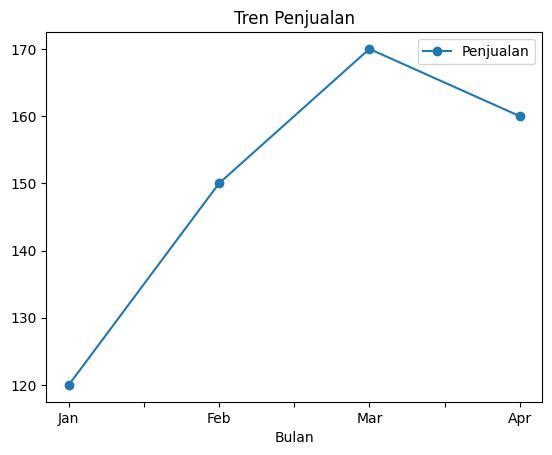

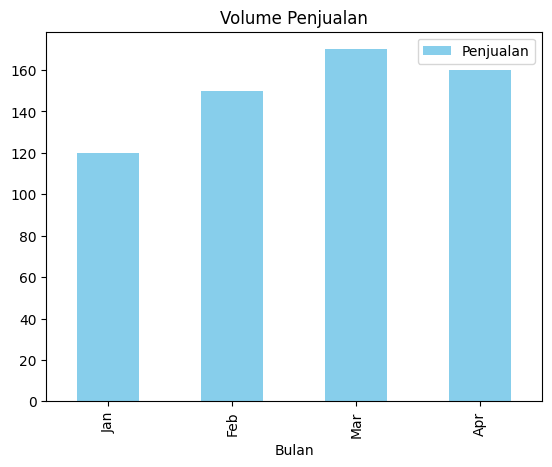

In [43]:
import matplotlib.pyplot as plt

df_grafik = pd.DataFrame({
    'Bulan': ['Jan', 'Feb', 'Mar', 'Apr'],
    'Penjualan': [120, 150, 170, 160]
}).set_index('Bulan')

df_grafik.plot(kind='line', marker='o', title='Tren Penjualan')
plt.show()

df_grafik.plot(kind='bar', color='skyblue', title='Volume Penjualan')
plt.show()


### Visualisasi Histogram


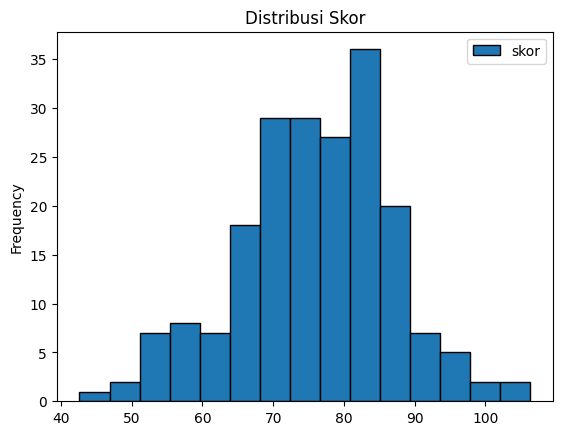

In [44]:
df_dist = pd.DataFrame({'skor': np.random.normal(75, 10, 200)})
df_dist.plot(kind='hist', bins=15, edgecolor='black', title='Distribusi Skor')
plt.show()


### Visualisasi Box Plot


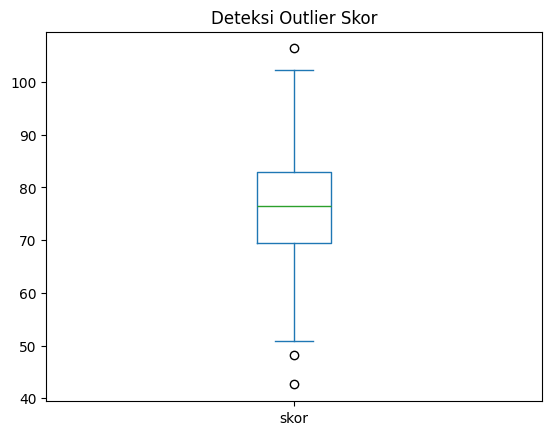

In [45]:
df_dist.plot.box(title='Deteksi Outlier Skor')
plt.show()


### Visualisasi Scatter Plot


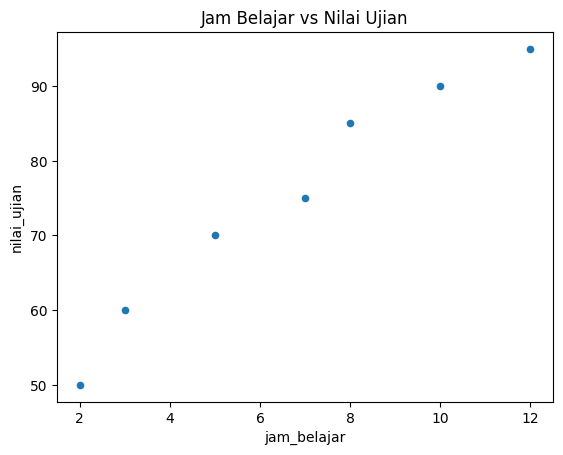

In [46]:
df_relasi = pd.DataFrame({
    'jam_belajar': [2, 3, 5, 7, 8, 10, 12],
    'nilai_ujian': [50, 60, 70, 75, 85, 90, 95]
})
df_relasi.plot.scatter(x='jam_belajar', y='nilai_ujian', title='Jam Belajar vs Nilai Ujian')
plt.show()


### Membaca Data Excel & JSON


In [47]:
json_text = '[{"id": 1, "produk": "A", "harga": 1000}, {"id": 2, "produk": "B", "harga": 2000}]'
df_json = pd.read_json(io.StringIO(json_text))
print("Hasil read_json:\n", df_json)


Hasil read_json:
    id produk  harga
0   1      A   1000
1   2      B   2000


### Membaca Tabel HTML


In [48]:
html_data = '''
<table>
  <tr><th>Kota</th><th>Provinsi</th></tr>
  <tr><td>Yogyakarta</td><td>DIY</td></tr>
  <tr><td>Surabaya</td><td>Jawa Timur</td></tr>
</table>
'''
tabel_web = pd.read_html(io.StringIO(html_data))
tabel_web[0]


,Kota,Provinsi
0,Yogyakarta,DIY
1,Surabaya,Jawa Timur


### Ekspor ke CSV & Excel


In [49]:
df_clean.to_csv('cleaned_dataset.csv', index=False)
print("Dataset berhasil diekspor ke cleaned_dataset.csv")


Dataset berhasil diekspor ke cleaned_dataset.csv


### Kustomisasi Tampilan Pandas


In [50]:
pd.set_option('display.max_columns', 10)
pd.set_option('display.max_rows', 10)
pd.set_option('display.float_format', '{:.2f}'.format)
print("Pengaturan display diperbarui.")


Pengaturan display diperbarui.


### Optimasi Penggunaan Memori


In [51]:
df_besar = pd.DataFrame({
    'id': np.arange(1000, dtype='int64'),
    'skor': np.random.randn(1000).astype('float64'),
    'kategori': np.random.choice(['A', 'B', 'C'], size=1000)
})

mem_sebelum = df_besar.memory_usage(deep=True).sum() / 1024

df_besar['id'] = pd.to_numeric(df_besar['id'], downcast='unsigned')
df_besar['skor'] = pd.to_numeric(df_besar['skor'], downcast='float')
df_besar['kategori'] = df_besar['kategori'].astype('category')

mem_sesudah = df_besar.memory_usage(deep=True).sum() / 1024
hemat = ((mem_sebelum - mem_sesudah) / mem_sebelum) * 100
print(f"Penghematan memori: {hemat:.1f}% ({mem_sebelum:.2f} KB -> {mem_sesudah:.2f} KB)")


Penghematan memori: 89.0% (64.58 KB -> 7.11 KB)


### Shifting dan Lagging Data (.shift & .diff)


In [52]:
ts_data = pd.DataFrame({
    'hari': ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat'],
    'harga': [100, 105, 102, 110, 115]
})

ts_data['harga_kemarin'] = ts_data['harga'].shift(1)
ts_data['selisih_diff'] = ts_data['harga'].diff()
ts_data['persen_perubahan'] = ts_data['harga'].pct_change() * 100
ts_data


,hari,harga,harga_kemarin,selisih_diff,persen_perubahan
0,Senin,100,NaN,NaN,NaN
1,Selasa,105,100.00,5.00,5.00
2,Rabu,102,105.00,-3.00,-2.86
3,Kamis,110,102.00,8.00,7.84
4,Jumat,115,110.00,5.00,4.55


### Rolling Windows dan Moving Average


In [53]:
saham = pd.DataFrame({'harga': [50, 52, 55, 53, 58, 62, 60, 65, 70, 68]})
saham['ma_3'] = saham['harga'].rolling(window=3).mean()
saham['std_3'] = saham['harga'].rolling(window=3).std()
saham


,harga,ma_3,std_3
0,50,NaN,NaN
1,52,NaN,NaN
2,55,52.33,2.52
3,53,53.33,1.53
4,58,55.33,2.52
5,62,57.67,4.51
6,60,60.00,2.00
7,65,62.33,2.52
8,70,65.00,5.00
9,68,67.67,2.52


### Expanding Windows


In [54]:
aliran_kas = pd.DataFrame({'kas_masuk': [1000, 1500, 2000, 1200, 1800]})
aliran_kas['kumulatif_total'] = aliran_kas['kas_masuk'].expanding().sum()
aliran_kas['rata_rata_berjalan'] = aliran_kas['kas_masuk'].expanding().mean()
aliran_kas


,kas_masuk,kumulatif_total,rata_rata_berjalan
0,1000,1000.00,1000.00
1,1500,2500.00,1250.00
2,2000,4500.00,1500.00
3,1200,5700.00,1425.00
4,1800,7500.00,1500.00


### GroupBy Transform


In [55]:
karyawan = pd.DataFrame({
    'divisi': ['IT', 'IT', 'HR', 'HR', 'Finance'],
    'gaji': [8000000, 12000000, 5000000, 6000000, 9000000]
})

karyawan['rata_divisi'] = karyawan.groupby('divisi')['gaji'].transform('mean')
karyawan['deviasi_gaji'] = karyawan['gaji'] - karyawan['rata_divisi']
karyawan


,divisi,gaji,rata_divisi,deviasi_gaji
0,IT,8000000,10000000.00,-2000000.00
1,IT,12000000,10000000.00,2000000.00
2,HR,5000000,5500000.00,-500000.00
3,HR,6000000,5500000.00,500000.00
4,Finance,9000000,9000000.00,0.00


### GroupBy Filter


In [56]:
# Memfilter grup yang total anggotanya > 1
karyawan.groupby('divisi').filter(lambda x: len(x) > 1)


,divisi,gaji,rata_divisi,deviasi_gaji
0,IT,8000000,10000000.00,-2000000.00
1,IT,12000000,10000000.00,2000000.00
2,HR,5000000,5500000.00,-500000.00
3,HR,6000000,5500000.00,500000.00


### Hierarchical Indexing (MultiIndex)


In [57]:
arrays = [
    ['Jogja', 'Jogja', 'Jakarta', 'Jakarta'],
    ['2025', '2026', '2025', '2026']
]
idx = pd.MultiIndex.from_arrays(arrays, names=['Kota', 'Tahun'])
df_multi = pd.DataFrame({'Pendapatan': [500, 650, 1200, 1400], 'Beban': [300, 400, 800, 950]}, index=idx)
df_multi


Pendapatan  Beban
Kota    Tahun                   
Jogja   2025          500    300
        2026          650    400
Jakarta 2025         1200    800
        2026         1400    950

### MultiIndex Slicing & Cross-Section (.xs)


In [58]:
print("Data kota Jogja:\n", df_multi.loc['Jogja'])
print("\nCross-section semua kota tahun 2026:\n", df_multi.xs('2026', level='Tahun'))


Data kota Jogja:
        Pendapatan  Beban
Tahun                   
2025          500    300
2026          650    400

Cross-section semua kota tahun 2026:
          Pendapatan  Beban
Kota                      
Jogja           650    400
Jakarta        1400    950


### Reshaping dengan Stack dan Unstack


In [59]:
df_unstacked = df_multi.unstack(level='Tahun')
print("Setelah unstack Tahun:\n", df_unstacked)

df_restacked = df_unstacked.stack(future_stack=True)
print("\nSetelah stack kembali:\n", df_restacked)


Setelah unstack Tahun:
         Pendapatan       Beban     
Tahun         2025  2026  2025 2026
Kota                               
Jakarta       1200  1400   800  950
Jogja          500   650   300  400

Setelah stack kembali:
                Pendapatan  Beban
Kota    Tahun                   
Jakarta 2025         1200    800
        2026         1400    950
Jogja   2025          500    300
        2026          650    400


### Reshaping Melt (Unpivoting)


In [60]:
lebar_df = pd.DataFrame({
    'produk': ['A', 'B'],
    'q1': [100, 150],
    'q2': [120, 170]
})

pd.melt(lebar_df, id_vars=['produk'], var_name='kuartal', value_name='penjualan')


,produk,kuartal,penjualan
0,A,q1,100
1,B,q1,150
2,A,q2,120
3,B,q2,170


### Explode Kolom List Bersarang


In [61]:
user_hobi = pd.DataFrame({
    'user': ['Aria', 'Budi'],
    'hobi': [['coding', 'gaming', 'music'], ['reading', 'coffee']]
})

user_hobi.explode('hobi').reset_index(drop=True)


,user,hobi
0,Aria,coding
1,Aria,gaming
2,Aria,music
3,Budi,reading
4,Budi,coffee


### Ekstraksi String dengan Regex (.str.extract)


In [62]:
kontak_df = pd.DataFrame({
    'info': ['Aria: 0812345678, DIY', 'Budi: 0898765432, JKT']
})

pola = r'(?P<Nama>[A-Za-z]+):\s*(?P<Telepon>\d+),\s*(?P<Wilayah>[A-Z]+)'
kontak_df['info'].str.extract(pola)


,Nama,Telepon,Wilayah
0,Aria,0812345678,DIY
1,Budi,0898765432,JKT


### Pencarian Pola Regex (.str.contains)


In [63]:
log_df = pd.DataFrame({
    'log': ['ERROR 404: Not Found', 'INFO: Server started', 'WARNING: High memory', 'ERROR 500: Internal']
})

log_df[log_df['log'].str.contains(r'ERROR\s*\d+', regex=True)]


,log
0,ERROR 404: Not Found
3,ERROR 500: Internal


### Categorical Data & Ordered Categories


In [64]:
ukuran_kategori = pd.Categorical(['M', 'XL', 'S', 'L', 'M'], categories=['S', 'M', 'L', 'XL'], ordered=True)
df_ukuran = pd.DataFrame({'size': ukuran_kategori})

print("Kategori terurut:", df_ukuran['size'].cat.categories)
print("Urutan terendah ke tertinggi:\n", df_ukuran.sort_values(by='size'))


Kategori terurut: Index(['S', 'M', 'L', 'XL'], dtype='str')
Urutan terendah ke tertinggi:
   size
2    S
0    M
4    M
3    L
1   XL


### Binning Nilai dengan pd.cut


In [65]:
nilai_mhs = pd.DataFrame({'nilai': [45, 62, 78, 88, 95, 54, 73]})
kategori_huruf = ['D', 'C', 'B', 'A']
batas = [0, 55, 70, 85, 100]

nilai_mhs['grade'] = pd.cut(nilai_mhs['nilai'], bins=batas, labels=kategori_huruf)
nilai_mhs


,nilai,grade
0,45,D
1,62,C
2,78,B
3,88,A
4,95,A
5,54,D
6,73,B


### Quantile Binning dengan pd.qcut


In [66]:
pendapatan = pd.DataFrame({'gaji': [3, 4, 5, 7, 9, 12, 15, 20, 25, 30]})
pendapatan['kuartil'] = pd.qcut(pendapatan['gaji'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
pendapatan


,gaji,kuartil
0,3,Q1
1,4,Q1
2,5,Q1
3,7,Q2
4,9,Q2
5,12,Q3
6,15,Q3
7,20,Q4
8,25,Q4
9,30,Q4


### Deteksi Outlier dengan Metode IQR


In [67]:
data_outlier = pd.Series([10, 12, 11, 13, 12, 11, 100, 14, 12, -50])

Q1 = data_outlier.quantile(0.25)
Q3 = data_outlier.quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outliers = data_outlier[(data_outlier < batas_bawah) | (data_outlier > batas_atas)]
print(f"Batas normal: [{batas_bawah:.1f}, {batas_atas:.1f}]")
print("Pencilan (Outliers) ditemukan:\n", outliers)


Batas normal: [8.4, 15.4]
Pencilan (Outliers) ditemukan:
 6    100
9    -50
dtype: int64


### Method Chaining dan .pipe()


In [68]:
def hitung_pajak(df_in):
    df_out = df_in.copy()
    df_out['pajak'] = df_out['omset'] * 0.11
    return df_out

hasil_chain = (
    df_sales
    .query("omset > 1300")
    .pipe(hitung_pajak)
    .sort_values("pajak", ascending=False)
    .reset_index(drop=True)
)
hasil_chain


,cabang,produk,omset,pajak
0,Semarang,A,2200,242.00
1,Jogja,B,2000,220.00
2,Solo,B,1800,198.00
3,Jogja,A,1500,165.00


### Menggabungkan Data dengan .combine_first()


In [69]:
df_lama = pd.DataFrame({'id': [1, 2, 3], 'status': ['aktif', np.nan, 'pending']})
df_baru = pd.DataFrame({'id': [1, 2, 3], 'status': ['aktif', 'aktif', 'aktif']})

df_lama.combine_first(df_baru)


,id,status
0,1,aktif
1,2,aktif
2,3,pending


### Ranking Data (.rank)


In [70]:
skor_lomba = pd.DataFrame({'skor': [85, 90, 85, 95, 70]})
skor_lomba['rank_default'] = skor_lomba['skor'].rank(ascending=False)
skor_lomba['rank_dense'] = skor_lomba['skor'].rank(ascending=False, method='dense')
skor_lomba


,skor,rank_default,rank_dense
0,85,3.50,3.00
1,90,2.00,2.00
2,85,3.50,3.00
3,95,1.00,1.00
4,70,5.00,4.00


### Matriks Korelasi dan Kovarians


In [71]:
data_keuangan = pd.DataFrame({
    'iklan': [10, 20, 30, 40, 50],
    'penjualan': [25, 45, 60, 80, 110],
    'komplain': [5, 4, 3, 2, 1]
})

print("Matriks Korelasi Pearson:\n", data_keuangan.corr())
print("\nMatriks Kovarians:\n", data_keuangan.cov())


Matriks Korelasi Pearson:
            iklan  penjualan  komplain
iklan       1.00       0.99     -1.00
penjualan   0.99       1.00     -0.99
komplain   -1.00      -0.99      1.00

Matriks Kovarians:
            iklan  penjualan  komplain
iklan     250.00     512.50    -25.00
penjualan 512.50    1067.50    -51.25
komplain  -25.00     -51.25      2.50


### Integrasi Database SQL (SQLite)


In [72]:
conn = sqlite3.connect(':memory:')
df_sales.to_sql('tabel_sales', conn, index=False, if_exists='replace')

df_dari_sql = pd.read_sql("SELECT cabang, SUM(omset) as total_omset FROM tabel_sales GROUP BY cabang", conn)
conn.close()

df_dari_sql


,cabang,total_omset
0,Jogja,3500
1,Semarang,2200
2,Solo,3000


### Pembacaan Data Ukuran Besar (Chunksize)


In [73]:
csv_besar = '''angka,label\n1,A\n2,B\n3,C\n4,D\n5,E'''
ringkasan_chunks = []

for chunk in pd.read_csv(io.StringIO(csv_besar), chunksize=2):
    ringkasan_chunks.append(chunk['angka'].sum())

print("Total sum per chunk:", ringkasan_chunks)
print("Total keseluruhan  :", sum(ringkasan_chunks))


Total sum per chunk: [np.int64(3), np.int64(7), np.int64(5)]
Total keseluruhan  : 15


### Format Tampilan Data (Mata Uang & Persentase)


In [74]:
df_keuangan = pd.DataFrame({
    'transaksi': ['A', 'B', 'C'],
    'nominal': [1500000.5, 750000.0, 2300000.75],
    'margin': [0.152, 0.089, 0.215]
})

df_keuangan['nominal_rp'] = df_keuangan['nominal'].apply(lambda x: f"Rp {x:,.2f}")
df_keuangan['margin_persen'] = df_keuangan['margin'].apply(lambda x: f"{x * 100:.1f}%")
df_keuangan


,transaksi,nominal,margin,nominal_rp,margin_persen
0,A,1500000.50,0.15,"Rp 1,500,000.50",15.2%
1,B,750000.00,0.09,"Rp 750,000.00",8.9%
2,C,2300000.75,0.21,"Rp 2,300,000.75",21.5%


### Timezone dan Konversi Waktu


In [75]:
tgl_utc = pd.date_range('2026-01-01', periods=3, freq='D', tz='UTC')
df_tz = pd.DataFrame({'UTC': tgl_utc})
df_tz['WIB'] = df_tz['UTC'].dt.tz_convert('Asia/Jakarta')
df_tz


,UTC,WIB
0,2026-01-01 00:00:00+00:00,2026-01-01 07:00:00+07:00
1,2026-01-02 00:00:00+00:00,2026-01-02 07:00:00+07:00
2,2026-01-03 00:00:00+00:00,2026-01-03 07:00:00+07:00


### Periode Waktu dan PeriodIndex


In [76]:
tgl_harian = pd.date_range('2026-01-01', periods=5, freq='15D')
df_periode = pd.DataFrame({'tanggal': tgl_harian})

df_periode['bulan_periode'] = df_periode['tanggal'].dt.to_period('M')
df_periode['kuartal_periode'] = df_periode['tanggal'].dt.to_period('Q')
df_periode


,tanggal,bulan_periode,kuartal_periode
0,2026-01-01,2026-01,2026Q1
1,2026-01-16,2026-01,2026Q1
2,2026-01-31,2026-01,2026Q1
3,2026-02-15,2026-02,2026Q1
4,2026-03-02,2026-03,2026Q1
